# 05d · XGBoost hyper-parameter study with chronological validation

**Objective.** Notebook 05 uses one hand-chosen configuration. Here we ask whether a documented search changes the conclusion, **without ever touching the test period and without random (shuffled) folds**, which would leak the future into training for time series.

**Protocol (fixed before running).**
1. *Random search.* The default configuration plus a few random candidates from an explicit grid (`src/tuning.py::SEARCH_SPACE`) are fitted at one horizon (30 min, the middle of the four) on a thinned training set. Early stopping and ranking use the **validation** period only.
2. *Rolling-origin cross-validation.* The default and the best candidates are re-scored with an expanding window **inside the training period**: train on blocks `0..i-1`, validate on block `i`, with a gap of one maximum horizon so that no training target lies in the validation block. This protects against choosing a configuration that only suits the validation weeks.
3. *Decision rule.* The tuned configuration replaces the default only if its mean cross-validation MAE is lower by **more than 0.5 %**; otherwise the default is kept (differences below that are inside the noise of a single seed).
4. *Refit.* If a challenger is adopted it is refitted for all four horizons with the full training set and saved as `xgboost_tuned`; the test period is scored only in notebook 07a.

> **Provenance.** Search results are cached in `artifacts/metrics/`; `RETRAIN = False` reuses them.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, tabular as tb, tuning as tn, xgboost_model as xm, evaluation as ev, visualization as viz

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
N, HZ = len(ctx.sensor_ids), config.HORIZONS
lat, lon = graph.locations["latitude"].to_numpy(), graph.locations["longitude"].to_numpy()
RETRAIN = False
H = config.TUNE_HORIZON
ADOPT_THRESHOLD = 0.005          # relative CV improvement needed to replace the default (decided before running)
print(f"tuning horizon: {H * 5} min | search candidates: {config.TUNE_N_CONFIGS} + default | finalists: default + top {config.TUNE_TOP_K} | CV folds: {config.TUNE_CV_FOLDS}")
print("search space:", tn.SEARCH_SPACE)

tuning horizon: 30 min | search candidates: 12 + default | finalists: default + top 3 | CV folds: 3
search space: {'max_depth': [4, 6, 8, 10], 'min_child_weight': [5, 20, 50, 100], 'learning_rate': [0.05, 0.08, 0.12], 'subsample': [0.6, 0.8, 1.0], 'colsample_bytree': [0.5, 0.8, 1.0], 'reg_lambda': [1.0, 5.0, 20.0]}


## 1 · Data for the search

In [3]:
td = tb.build_tabular(ctx, lat, lon)
thin = np.arange(0, len(td.origin_sets["train"]), config.TUNE_TRAIN_THIN)          # extra thinning for the search
X_full, (r_full, ok_full, _) = td.design("train", H), td.targets("train", H)
rows_thin = tn.rows_for_origins(thin, N)
X_tr, r_tr, ok_tr = X_full.iloc[rows_thin], r_full[rows_thin], ok_full[rows_thin]
X_va, (r_va, ok_va, _) = td.design("val_fit", H), td.targets("val_fit", H)
print(f"search training rows: {int(ok_tr.sum()):,} (of {len(ok_full):,}) | validation rows: {int(ok_va.sum()):,}")
print(f"reference (persistence, residual 0): validation MAE {np.abs(r_va[ok_va]).mean():.3f} mph")

search training rows: 764,001 (of 2,471,787) | validation rows: 221,497
reference (persistence, residual 0): validation MAE 3.834 mph


## 2 · Stage 1: random search scored on the validation period

In [4]:
candidates = [("default", tn.default_candidate())] + [(f"cfg{i:02d}", c) for i, c in enumerate(tn.sample_configs(config.TUNE_N_CONFIGS), 1)]
res_path = config.METRICS_DIR / f"{config.tagged('xgb_tuning')}_search.json"
done = json.loads(res_path.read_text()) if (not RETRAIN and res_path.is_file()) else {}
for name, cfg in candidates:
    if name in done:
        continue
    sc = tn.fit_and_score(X_tr[ok_tr], r_tr[ok_tr], X_va[ok_va], r_va[ok_va], cfg)
    done[name] = {**cfg, **sc}; res_path.write_text(json.dumps(done))
    print(f"{name:8s} val MAE {sc['val_mae']:.4f} | best round {sc['best_iteration']:4d} | {sc['seconds']:5.1f}s | {cfg}")
search = pd.DataFrame(done).T.astype({"val_mae": float, "best_iteration": int}).sort_values("val_mae")
search["vs default (%)"] = 100 * (search.loc["default", "val_mae"] - search["val_mae"]) / search.loc["default", "val_mae"]
search.to_csv(config.METRICS_DIR / f"{config.tagged('xgb_tuning')}_search.csv")
display(search.round(4))

default  val MAE 3.0939 | best round  599 |  37.0s | {'max_depth': 8, 'min_child_weight': 20, 'learning_rate': 0.08, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5.0}


cfg01    val MAE 3.2071 | best round  600 |  22.2s | {'max_depth': 4, 'min_child_weight': 100, 'learning_rate': 0.08, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 20.0}


cfg02    val MAE 3.2437 | best round  600 |  23.6s | {'max_depth': 4, 'min_child_weight': 50, 'learning_rate': 0.05, 'subsample': 0.6, 'colsample_bytree': 0.8, 'reg_lambda': 20.0}


cfg03    val MAE 3.0988 | best round  361 |  21.6s | {'max_depth': 8, 'min_child_weight': 100, 'learning_rate': 0.12, 'subsample': 1.0, 'colsample_bytree': 0.8, 'reg_lambda': 1.0}


cfg04    val MAE 3.0915 | best round  587 |  39.9s | {'max_depth': 10, 'min_child_weight': 20, 'learning_rate': 0.08, 'subsample': 0.8, 'colsample_bytree': 0.5, 'reg_lambda': 20.0}


cfg05    val MAE 3.0824 | best round  393 |  28.6s | {'max_depth': 10, 'min_child_weight': 50, 'learning_rate': 0.08, 'subsample': 1.0, 'colsample_bytree': 0.8, 'reg_lambda': 5.0}


... (4 outputs left out)

cfg10    val MAE 3.1394 | best round  600 |  32.6s | {'max_depth': 6, 'min_child_weight': 5, 'learning_rate': 0.08, 'subsample': 0.6, 'colsample_bytree': 1.0, 'reg_lambda': 20.0}


cfg11    val MAE 3.0846 | best round  462 |  35.0s | {'max_depth': 10, 'min_child_weight': 50, 'learning_rate': 0.08, 'subsample': 1.0, 'colsample_bytree': 0.8, 'reg_lambda': 1.0}


cfg12    val MAE 3.0853 | best round  428 |  42.2s | {'max_depth': 10, 'min_child_weight': 20, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 1.0, 'reg_lambda': 1.0}


,max_depth,min_child_weight,learning_rate,subsample,colsample_bytree,reg_lambda,val_mae,best_iteration,seconds,vs default (%)
cfg05,10.0,50.0,0.08,1.0,0.8,5.0,3.0824,393,28.6,0.3711
cfg11,10.0,50.0,0.08,1.0,0.8,1.0,3.0846,462,35.0,0.3029
cfg12,10.0,20.0,0.05,0.8,1.0,1.0,3.0853,428,42.2,0.2796
cfg04,10.0,20.0,0.08,0.8,0.5,20.0,3.0915,587,39.9,0.0770
default,8.0,20.0,0.08,0.8,0.8,5.0,3.0939,599,37.0,0.0000
cfg07,10.0,100.0,0.05,0.8,0.5,20.0,3.0986,600,41.8,-0.1526
cfg03,8.0,100.0,0.12,1.0,0.8,1.0,3.0988,361,21.6,-0.1575
cfg08,8.0,20.0,0.05,1.0,0.8,20.0,3.1011,598,38.5,-0.2320
cfg09,8.0,100.0,0.12,0.6,0.8,5.0,3.1098,555,36.5,-0.5129
cfg06,6.0,5.0,0.05,0.8,1.0,1.0,3.1385,600,39.9,-1.4401


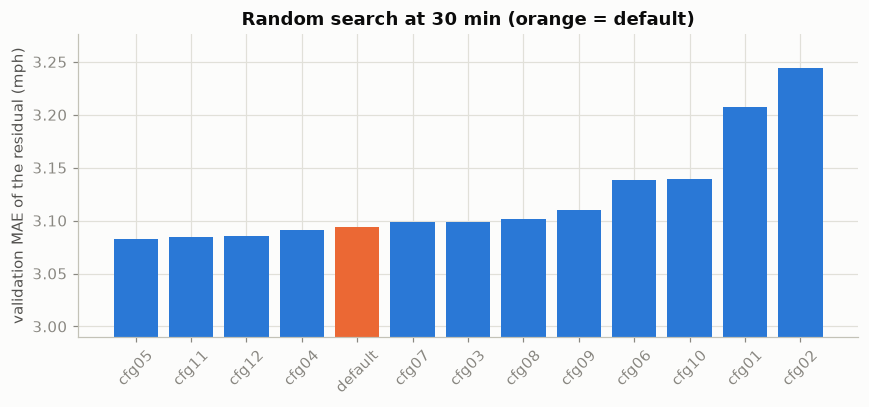

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#eb6834" if n == "default" else "#2a78d6" for n in search.index]
ax.bar(search.index, search["val_mae"], color=colors); ax.set_ylim(search["val_mae"].min() * 0.97, search["val_mae"].max() * 1.01)
ax.set_ylabel("validation MAE of the residual (mph)"); ax.set_title(f"Random search at {H * 5} min (orange = default)"); plt.xticks(rotation=45)
fig.tight_layout(); viz.save_figure(fig, "05d_search_validation_mae"); plt.show()

## 3 · Stage 2: rolling-origin cross-validation inside the training period

In [6]:
top = [n for n in search.index if n != "default"][:config.TUNE_TOP_K]
finalists = ["default"] + top
origins_thin = td.origin_sets["train"][thin]
folds = tn.rolling_origin_folds(origins_thin, config.TUNE_CV_FOLDS)
span = lambda pos: f"{ctx.timestamps[origins_thin[pos[0]]].date()} .. {ctx.timestamps[origins_thin[pos[-1]]].date()}"
for k, (a, b) in enumerate(folds, 1):
    print(f"fold {k}: train origins {span(a)} ({len(a):,}) -> validate {span(b)} ({len(b):,}) | last training target {ctx.timestamps[origins_thin[a[-1]] + config.MAX_HORIZON].date()} < first validation origin {ctx.timestamps[origins_thin[b[0]]].date()}")
cv_path = config.METRICS_DIR / f"{config.tagged('xgb_tuning')}_cv.json"
cv = json.loads(cv_path.read_text()) if (not RETRAIN and cv_path.is_file()) else {}
cfg_by_name = dict(candidates)
for name in finalists:
    if name in cv:
        continue
    maes = []
    for a, b in folds:
        ra, rb = tn.rows_for_origins(thin[a], N), tn.rows_for_origins(thin[b], N)
        oka, okb = ok_full[ra], ok_full[rb]
        maes.append(tn.fit_and_score(X_full.iloc[ra][oka], r_full[ra][oka], X_full.iloc[rb][okb], r_full[rb][okb], cfg_by_name[name])["val_mae"])
    cv[name] = maes; cv_path.write_text(json.dumps(cv)); print(f"{name:8s} fold MAEs {np.round(maes, 4)}")
cvt = pd.DataFrame({n: {"mean CV MAE": float(np.mean(v)), "std over folds": float(np.std(v)), **{f"fold {i + 1}": x for i, x in enumerate(v)}} for n, v in cv.items()}).T.sort_values("mean CV MAE")
cvt["vs default (%)"] = 100 * (cvt.loc["default", "mean CV MAE"] - cvt["mean CV MAE"]) / cvt.loc["default", "mean CV MAE"]
cvt.to_csv(config.METRICS_DIR / f"{config.tagged('xgb_tuning')}_cv.csv")
display(cvt.round(4))

fold 1: train origins 2012-03-01 .. 2012-03-21 (993) -> validate 2012-03-21 .. 2012-04-11 (995) | last training target 2012-03-21 < first validation origin 2012-03-21
fold 2: train origins 2012-03-01 .. 2012-04-11 (1,988) -> validate 2012-04-11 .. 2012-05-02 (995) | last training target 2012-04-11 < first validation origin 2012-04-11
fold 3: train origins 2012-03-01 .. 2012-05-02 (2,983) -> validate 2012-05-02 .. 2012-05-22 (996) | last training target 2012-05-02 < first validation origin 2012-05-02


default  fold MAEs [3.3175 3.2176 3.2225]


cfg05    fold MAEs [3.313  3.206  3.1876]


cfg11    fold MAEs [3.3093 3.21   3.1858]


cfg12    fold MAEs [3.3134 3.209  3.1989]


,mean CV MAE,std over folds,fold 1,fold 2,fold 3,vs default (%)
cfg11,3.2350,0.0534,3.3093,3.2100,3.1858,0.5388
cfg05,3.2355,0.0553,3.3130,3.2060,3.1876,0.5226
cfg12,3.2405,0.0518,3.3134,3.2090,3.1989,0.3719
default,3.2525,0.0460,3.3175,3.2176,3.2225,0.0000


## 4 · Decision

In [7]:
challenger = cvt.drop(index="default")["mean CV MAE"].idxmin()
gain = float(cvt.loc[challenger, "vs default (%)"]) / 100
adopt = gain > ADOPT_THRESHOLD
chosen = challenger if adopt else "default"
print(f"best challenger by CV: {challenger} ({100 * gain:+.2f} % vs default); adoption threshold {100 * ADOPT_THRESHOLD:.1f} % -> {'ADOPT' if adopt else 'KEEP THE DEFAULT'}")
print("chosen configuration:", cfg_by_name[chosen])
fold_wins = int(sum(np.array(cv[challenger]) < np.array(cv["default"])))
print(f"the challenger beats the default in {fold_wins} of {len(folds)} folds")
del X_full

best challenger by CV: cfg11 (+0.54 % vs default); adoption threshold 0.5 % -> ADOPT
chosen configuration: {'max_depth': 10, 'min_child_weight': 50, 'learning_rate': 0.08, 'subsample': 1.0, 'colsample_bytree': 0.8, 'reg_lambda': 1.0}
the challenger beats the default in 3 of 3 folds


## 5 · Refit the chosen configuration for all horizons (only if a challenger was adopted)

In [8]:
if not adopt:
    print("The default configuration was kept: no tuned model is produced and notebook 07a evaluates the notebook-05 XGBoost.")
else:
    PREFIX = "xgb_tuned"
    params = {**config.XGB_PARAMS, **cfg_by_name[chosen]}
    curves_path = config.METRICS_DIR / f"{config.tagged(PREFIX)}_validation_curves.json"
    models, fit_info = {}, {}
    if not RETRAIN and all(xm.model_path(h, PREFIX).is_file() for h in HZ) and curves_path.is_file():
        saved = json.loads(curves_path.read_text())
        for h in HZ:
            models[h] = xm.load_model(h, PREFIX); fit_info[h] = saved["fit_info"][str(h)]
        print("reloaded the saved tuned models")
    else:
        curves = {}
        for h in HZ:
            t0 = time.time()
            X_t, (r_t, ok_t, _) = td.design("train", h), td.targets("train", h)
            X_v, (r_v, ok_v, _) = td.design("val_fit", h), td.targets("val_fit", h)
            m = xm.fit_horizon_model(X_t[ok_t], r_t[ok_t], X_v[ok_v], r_v[ok_v], params)
            models[h] = m; curves[h] = m.evals_result()["validation_0"]["mae"]
            fit_info[h] = {"horizon_min": h * 5, "train_rows": int(ok_t.sum()), "best_iteration": int(m.best_iteration) + 1,
                           "val_residual_MAE": float(min(curves[h])), "seconds": round(time.time() - t0)}
            print(f"h={h:2d}: best iteration {fit_info[h]['best_iteration']}, validation residual MAE {fit_info[h]['val_residual_MAE']:.3f} mph, {fit_info[h]['seconds']}s")
            del X_t, X_v
        xm.save_models(models, {"seed": config.SEED, "tuned_overrides": cfg_by_name[chosen], "chosen": chosen, "fit_info": {str(k): v for k, v in fit_info.items()}}, prefix=PREFIX)
        curves_path.write_text(json.dumps({"curves": {str(k): v for k, v in curves.items()}, "fit_info": {str(k): v for k, v in fit_info.items()}}))
    for split in ("val", "test"):
        out = np.empty((len(td.origin_sets[split]), len(HZ), N), dtype=np.float32)
        for j, h in enumerate(HZ):
            out[:, j, :] = xm.predict_speed(models[h], td.design(split, h)).reshape(-1, N)
        assert np.isfinite(out).all()
        ev.save_predictions("xgboost_tuned", split, out, td.origin_sets[split], HZ, {"model": "xgboost_tuned", "overrides": cfg_by_name[chosen], "units": "mph", "run_mode": config.RUN_MODE})
    display(pd.DataFrame(fit_info).T)

h= 1: best iteration 380, validation residual MAE 2.168 mph, 82s


h= 3: best iteration 416, validation residual MAE 2.632 mph, 95s


h= 6: best iteration 500, validation residual MAE 3.027 mph, 100s


h=12: best iteration 568, validation residual MAE 3.451 mph, 113s


,horizon_min,train_rows,best_iteration,val_residual_MAE,seconds
1,5.0,2296387.0,380.0,2.168013,82.0
3,15.0,2296389.0,416.0,2.632055,95.0
6,30.0,2293530.0,500.0,3.026569,100.0
12,60.0,2293535.0,568.0,3.451426,113.0


## 6 · Validation comparison: default vs tuned

In [9]:
if adopt:
    val_preds = {}
    for m in ("persistence", "xgboost", "xgboost_tuned"):
        d = ev.load_predictions(m, "val"); assert np.array_equal(d["origins"], td.origin_sets["val"]); val_preds[m] = d["pred"]
    yv, mv = pp.gather_targets(ctx.speed, ctx.mask, td.origin_sets["val"], HZ)
    valid = ev.common_valid_mask(val_preds, mv)
    table = ev.metrics_by_horizon(val_preds, yv, valid, HZ)
    table.to_csv(config.METRICS_DIR / f"{config.tagged('xgboost_tuned')}_metrics_val.csv", index=False)
    display(table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE", "MAPE"]).round(3))
else:
    print("nothing to compare: the default was kept")

MAE                        RMSE                        MAPE  \
horizon_min       5      15     30     60     5      15     30     60     5    
model                                                                          
persistence    2.642  3.235  3.844  4.839  4.383  6.028  7.545  9.668  5.930   
xgboost        2.159  2.642  3.050  3.495  3.827  5.261  6.290  7.221  5.152   
xgboost_tuned  2.161  2.638  3.037  3.457  3.826  5.244  6.263  7.156  5.154   

                                     
horizon_min       15     30      60  
model                                
persistence    7.832  9.875  13.203  
xgboost        7.032  8.888  10.829  
xgboost_tuned  7.011  8.829  10.597